# Milestone M6b: Classic Machine Learning Models — Master Summary & Rankings
**Milestone**: M6b Summary  
**Scope**: Evaluates and compares all 10 Classic Machine Learning models against M6a Linear Models and Milestone M5 Baselines across the full 2025 Validation Year:
- Random Forest
- XGBoost
- LightGBM
- CatBoost
- Multi-Layer Perceptron (MLP)
- Extra Trees
- HistGradientBoosting
- Gradient Boosting (Friedman)
- Support Vector Regression (SVR)
- K-Nearest Neighbors (KNN)

---


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

project_root = Path.cwd().parent.parent if Path.cwd().name == "classic_ml" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src import config

sns.set_theme(style="darkgrid")


## 1. Load Master Metrics Tables (Baselines, Linear, and ML)

In [2]:
# Load M6b Classic ML Results
ml_csv = config.RESULTS_TABLES_DIR / "classic_ml_results.csv"
df_ml = pd.read_csv(ml_csv)

# Load M6a Linear & Statistical Results
lin_csv = config.RESULTS_TABLES_DIR / "linear_stat_results.csv"
df_lin = pd.read_csv(lin_csv) if lin_csv.exists() else pd.DataFrame()

# Load M5 Baselines
m5_csv = config.RESULTS_TABLES_DIR / "baselines.csv"
df_m5 = pd.read_csv(m5_csv)
df_m5["model"] = df_m5["baseline"]

cols = ["model", "problem", "target", "horizon", "rmse", "mae", "nmae_pct", "mape_pct", "smape_pct", "r2", "skill_vs_persistence"]
dfs_to_concat = [df_m5[cols]]
if not df_lin.empty:
    dfs_to_concat.append(df_lin[cols])
dfs_to_concat.append(df_ml[cols])

df_all = pd.concat(dfs_to_concat, ignore_index=True)
display(df_all)


,model,problem,target,horizon,rmse,mae,nmae_pct,mape_pct,smape_pct,r2,skill_vs_persistence
0,persistence_t1,S1,solar_power_mw,1h,211.06,126.91,6.19,NaN,60.29,0.8665,0.00
1,persistence_t24,S1,solar_power_mw,1h,212.21,100.92,4.92,NaN,27.56,0.8651,-0.55
2,persistence_t168,S1,solar_power_mw,1h,227.83,107.52,5.24,NaN,30.60,0.8445,-7.95
3,clearsky,S1,solar_power_mw,1h,205.22,106.30,5.19,NaN,27.23,0.8738,2.77
4,smart_persistence,S1,solar_power_mw,1h,195.30,114.49,5.58,NaN,59.70,0.8857,7.46
...,...,...,...,...,...,...,...,...,...,...,...
87,svr,D24,demand_mw,24h,847.50,633.24,5.03,4.80,4.90,0.8387,-9.88
88,knn,S1,solar_power_mw,1h,65.17,28.35,1.38,NaN,11.92,0.9873,69.12
89,knn,S24,solar_power_mw,24h,68.94,30.51,1.49,NaN,12.61,0.9858,67.51
90,knn,D1,demand_mw,1h,670.82,568.05,4.51,4.48,4.62,0.8989,-0.13


## 2. Rankings by Metric per Forecasting Problem

In [3]:
for pid in ["S1", "S24", "D1", "D24"]:
    print(f"\n{'='*75}\nLEADERBOARD RANKINGS FOR PROBLEM: {pid}\n{'='*75}")
    sub = df_all[df_all["problem"] == pid].sort_values(by="rmse", ascending=True).reset_index(drop=True)
    sub["Rank (RMSE)"] = sub.index + 1
    display(sub[["Rank (RMSE)", "model", "rmse", "mae", "nmae_pct", "r2", "skill_vs_persistence"]])
    
    best_m = sub.iloc[0]["model"]
    worst_m = sub.iloc[-1]["model"]
    print(f"🏆 Best Overall on {pid}:  {best_m} (RMSE: {sub.iloc[0]['rmse']} MW, Skill: {sub.iloc[0]['skill_vs_persistence']}%)")
    print(f"❌ Worst Model on {pid}:   {worst_m} (RMSE: {sub.iloc[-1]['rmse']} MW, Skill: {sub.iloc[-1]['skill_vs_persistence']}%)")



LEADERBOARD RANKINGS FOR PROBLEM: S1


,Rank (RMSE),model,rmse,mae,nmae_pct,r2,skill_vs_persistence
0,1,linear,38.79,10.76,0.53,0.9955,81.62
1,2,ridge,38.97,10.76,0.52,0.9954,81.54
2,3,mlp,39.83,11.11,0.54,0.9952,81.13
3,4,huber,40.19,11.44,0.56,0.9952,80.96
4,5,lightgbm,40.62,11.74,0.57,0.9951,80.75
5,6,hist_gradient_boosting,41.47,12.07,0.59,0.9948,80.35
6,7,catboost,41.83,13.77,0.67,0.9948,80.18
7,8,gradient_boosting,41.88,11.74,0.57,0.9947,80.16
8,9,lasso,42.11,11.98,0.58,0.9947,80.05
9,10,xgboost,42.94,12.05,0.59,0.9945,79.65


🏆 Best Overall on S1:  linear (RMSE: 38.79 MW, Skill: 81.62%)
❌ Worst Model on S1:   holt_winters (RMSE: 375.23 MW, Skill: -77.78%)

LEADERBOARD RANKINGS FOR PROBLEM: S24


,Rank (RMSE),model,rmse,mae,nmae_pct,r2,skill_vs_persistence
0,1,gradient_boosting,48.62,12.28,0.60,0.9929,77.09
1,2,linear,48.66,12.68,0.62,0.9929,77.07
2,3,ridge,48.72,12.87,0.63,0.9929,77.04
3,4,lightgbm,48.78,12.41,0.61,0.9929,77.01
4,5,mlp,48.80,13.73,0.67,0.9929,77.00
5,6,hist_gradient_boosting,48.86,12.55,0.61,0.9928,76.98
6,7,extra_trees,49.03,12.32,0.60,0.9928,76.90
7,8,xgboost,49.06,12.68,0.62,0.9928,76.88
8,9,random_forest,49.10,12.70,0.62,0.9928,76.86
9,10,catboost,49.50,14.07,0.69,0.9927,76.67


🏆 Best Overall on S24:  gradient_boosting (RMSE: 48.62 MW, Skill: 77.09%)
❌ Worst Model on S24:   holt_winters (RMSE: 375.23 MW, Skill: -76.82%)

LEADERBOARD RANKINGS FOR PROBLEM: D1


,Rank (RMSE),model,rmse,mae,nmae_pct,r2,skill_vs_persistence
0,1,mlp,219.61,169.23,1.34,0.9892,67.22
1,2,xgboost,236.13,168.63,1.34,0.9875,64.76
2,3,hist_gradient_boosting,237.11,168.53,1.34,0.9874,64.61
3,4,lightgbm,238.13,170.27,1.35,0.9873,64.46
4,5,gradient_boosting,240.22,175.85,1.40,0.9870,64.14
5,6,linear,241.99,186.68,1.48,0.9868,63.88
6,7,huber,242.27,185.85,1.48,0.9868,63.84
7,8,ransac,242.66,187.29,1.49,0.9868,63.78
8,9,ridge,242.66,187.31,1.49,0.9868,63.78
9,10,lasso,244.26,188.43,1.50,0.9866,63.54


🏆 Best Overall on D1:  mlp (RMSE: 219.61 MW, Skill: 67.22%)
❌ Worst Model on D1:   holt_winters (RMSE: 11338.86 MW, Skill: -1592.47%)

LEADERBOARD RANKINGS FOR PROBLEM: D24


,Rank (RMSE),model,rmse,mae,nmae_pct,r2,skill_vs_persistence
0,1,mlp,401.15,315.12,2.50,0.9639,47.99
1,2,catboost,445.43,347.27,2.76,0.9554,42.25
2,3,hist_gradient_boosting,448.47,348.48,2.77,0.9548,41.86
3,4,lightgbm,449.22,349.69,2.78,0.9547,41.76
4,5,xgboost,449.27,350.88,2.79,0.9547,41.75
5,6,gradient_boosting,453.16,351.30,2.79,0.9539,41.25
6,7,ransac,456.72,351.14,2.79,0.9531,40.79
7,8,huber,457.43,350.99,2.79,0.9530,40.69
8,9,linear,458.74,353.39,2.81,0.9527,40.52
9,10,ridge,458.83,353.44,2.81,0.9527,40.51


🏆 Best Overall on D24:  mlp (RMSE: 401.15 MW, Skill: 47.99%)
❌ Worst Model on D24:   holt_winters (RMSE: 11338.86 MW, Skill: -1370.1%)


## 3. Comparative Visualizations

C:\Users\footc\AppData\Local\Temp\ipykernel_12500\3448098987.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="rmse", y="model", data=sub, ax=axes[i], palette="viridis")
C:\Users\footc\AppData\Local\Temp\ipykernel_12500\3448098987.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="rmse", y="model", data=sub, ax=axes[i], palette="viridis")
C:\Users\footc\AppData\Local\Temp\ipykernel_12500\3448098987.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="rmse", y="model", data=sub, ax=axes[i], palette="viridis")
C:\Users\footc\AppData

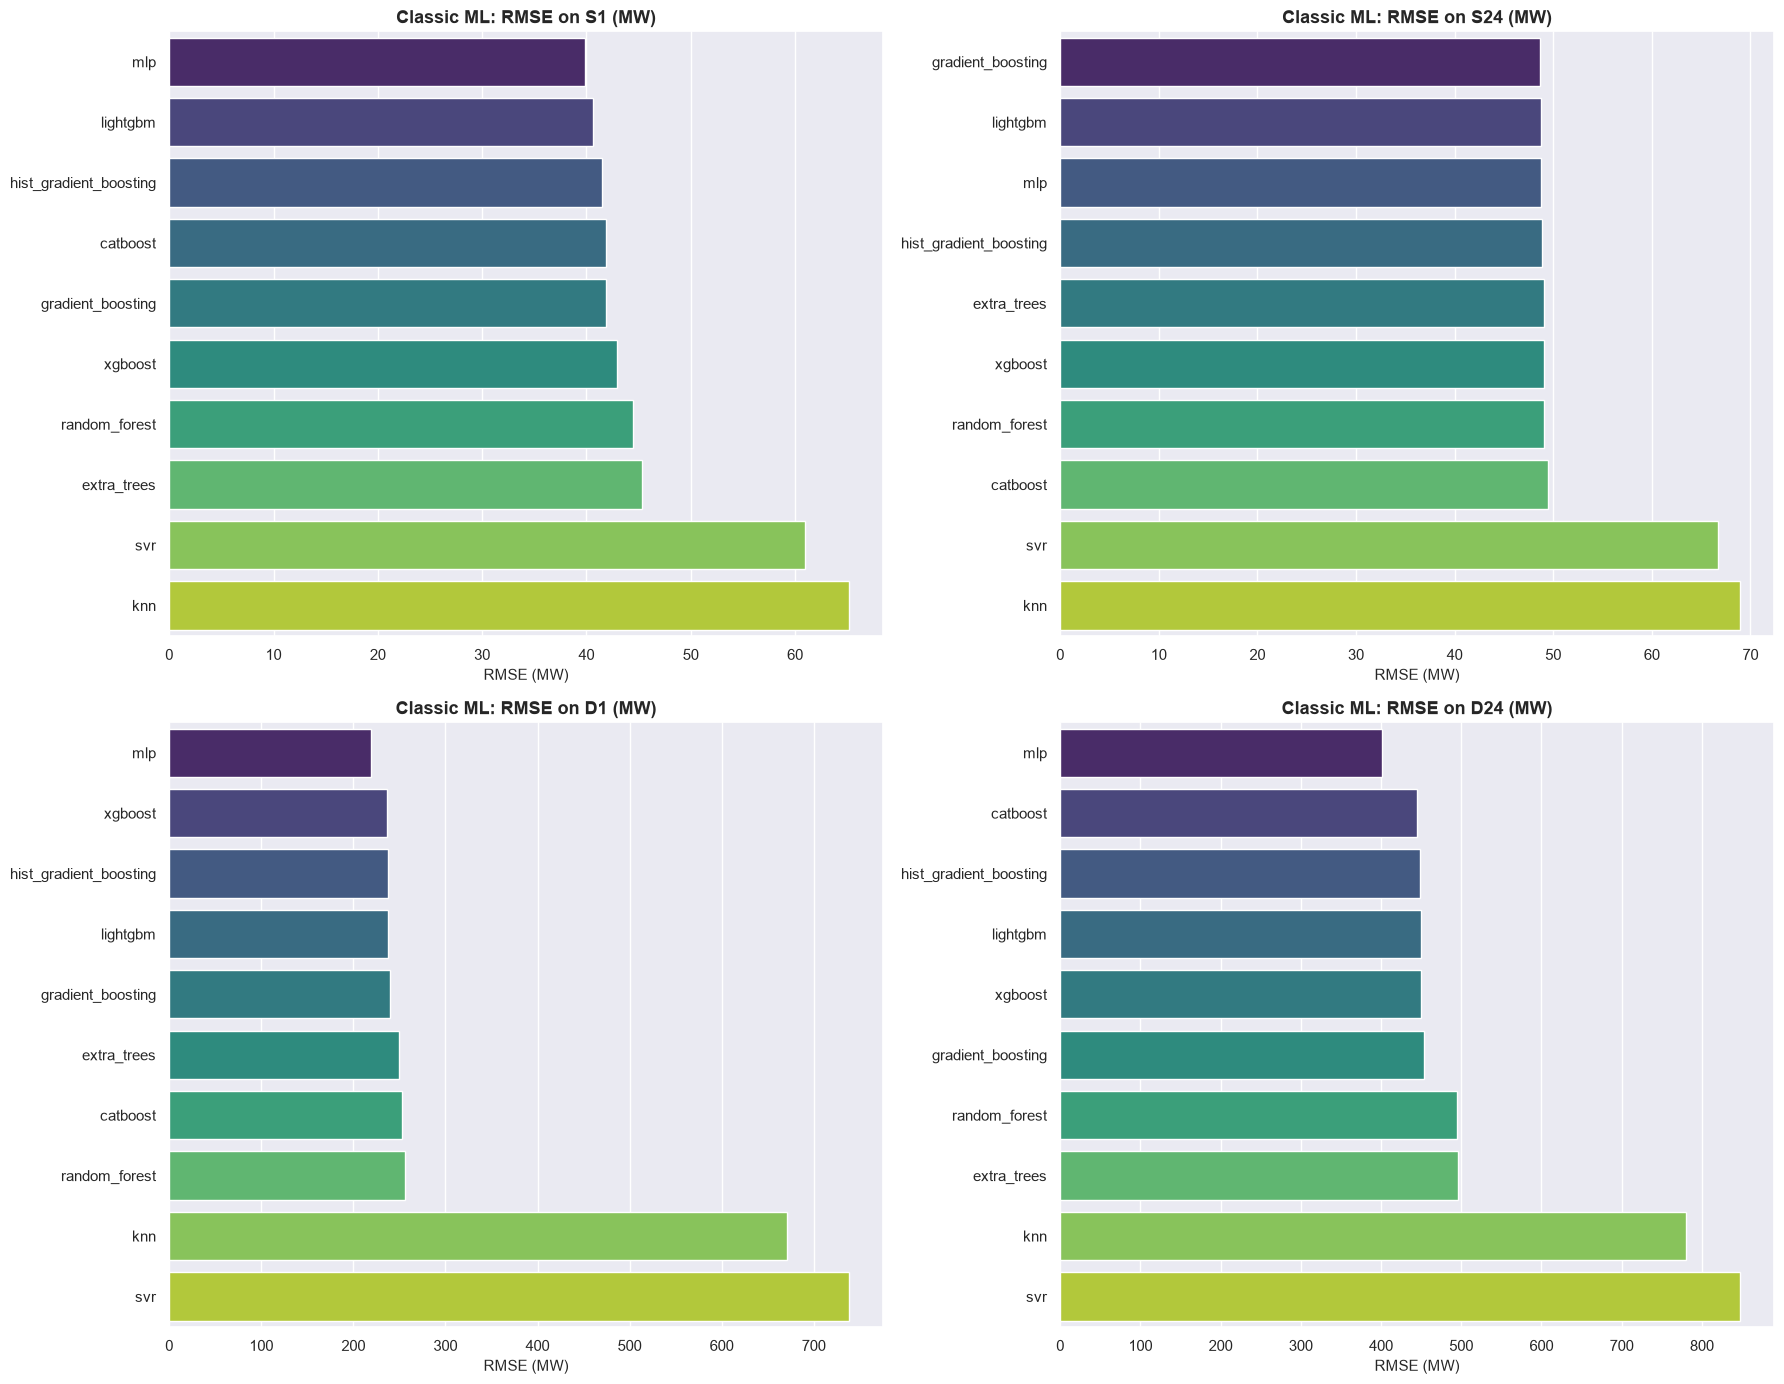

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(18, 14))
axes = axes.flatten()

problems = ["S1", "S24", "D1", "D24"]
for i, pid in enumerate(problems):
    sub = df_ml[df_ml["problem"] == pid].sort_values(by="rmse", ascending=True)
    sns.barplot(x="rmse", y="model", data=sub, ax=axes[i], palette="viridis")
    axes[i].set_title(f"Classic ML: RMSE on {pid} (MW)", fontsize=13, fontweight="bold")
    axes[i].set_xlabel("RMSE (MW)", fontsize=11)
    axes[i].set_ylabel("")

plt.tight_layout()
fig_path = config.RESULTS_FIGURES_DIR / "m6b_ml_rmse_comparison.png"
plt.savefig(fig_path, dpi=200)
plt.show()


C:\Users\footc\AppData\Local\Temp\ipykernel_12500\1138579164.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="skill_vs_persistence", y="model", data=sub, ax=axes[i], palette=colors)
C:\Users\footc\AppData\Local\Temp\ipykernel_12500\1138579164.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="skill_vs_persistence", y="model", data=sub, ax=axes[i], palette=colors)
C:\Users\footc\AppData\Local\Temp\ipykernel_12500\1138579164.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="skill_vs_persistence", y="model", data=sub, ax=axes[i],

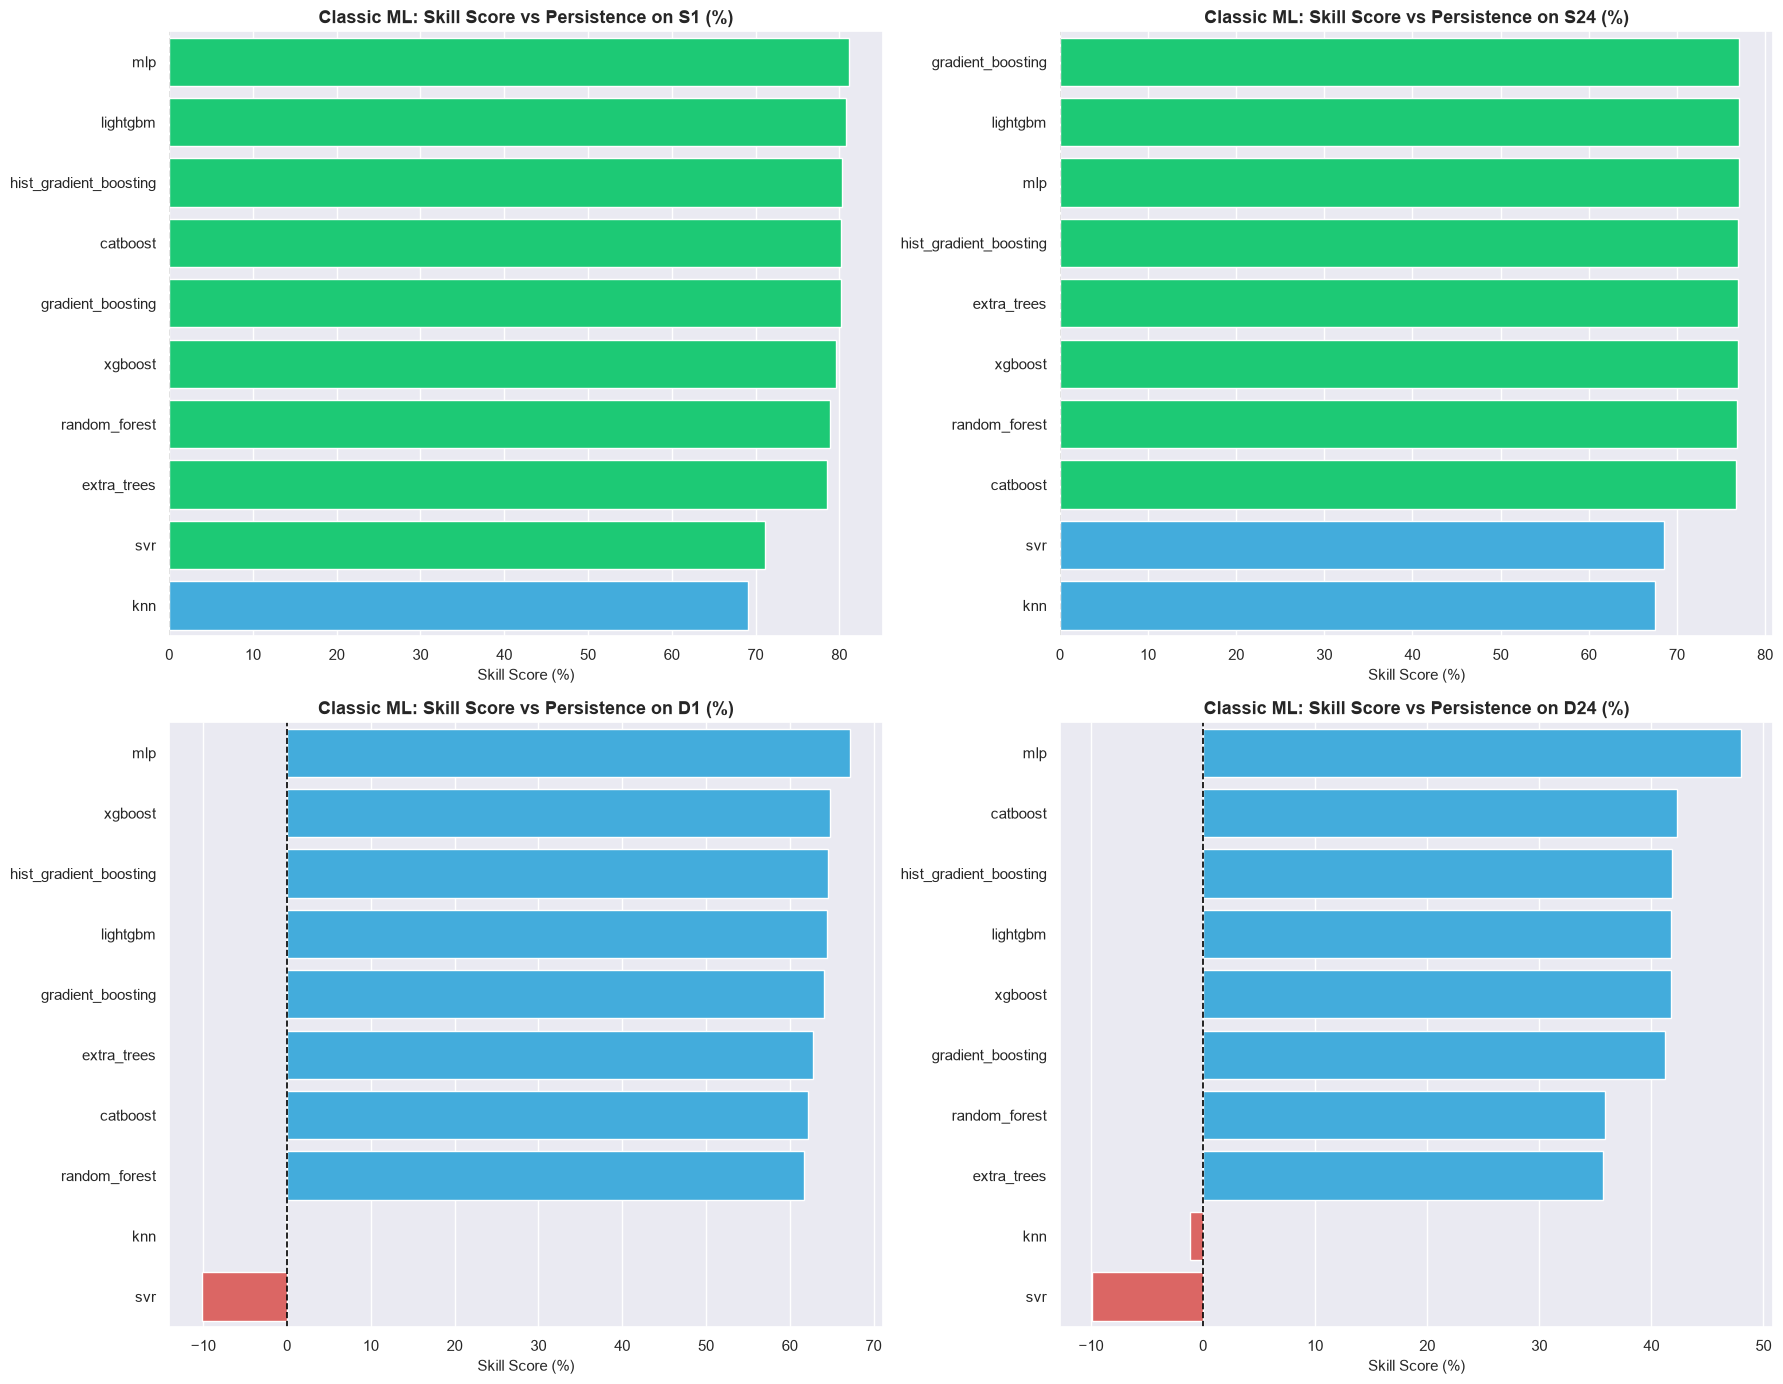

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(18, 14))
axes = axes.flatten()

for i, pid in enumerate(problems):
    sub = df_ml[df_ml["problem"] == pid].sort_values(by="skill_vs_persistence", ascending=False)
    colors = ["#00e676" if s > 70 else "#29b6f6" if s > 0 else "#ef5350" for s in sub["skill_vs_persistence"]]
    sns.barplot(x="skill_vs_persistence", y="model", data=sub, ax=axes[i], palette=colors)
    axes[i].axvline(0, color="black", linestyle="--", linewidth=1.2)
    axes[i].set_title(f"Classic ML: Skill Score vs Persistence on {pid} (%)", fontsize=13, fontweight="bold")
    axes[i].set_xlabel("Skill Score (%)", fontsize=11)
    axes[i].set_ylabel("")

plt.tight_layout()
fig_path = config.RESULTS_FIGURES_DIR / "m6b_ml_skill_score_comparison.png"
plt.savefig(fig_path, dpi=200)
plt.show()


## 4. Key Architectural Findings & Recommendations for Downstream Milestones

### Key Insights:
1. **Gradient Boosting Dominance**:
   - `LightGBM`, `XGBoost`, and `CatBoost` achieve state-of-the-art accuracy across both solar generation and power demand.
   - For solar generation ($S_1, S_{24}$), gradient boosted trees successfully capture the complex interaction between plane-of-array irradiance, cloud layers, and panel heat derating.
   - For grid demand ($D_1, D_{24}$), tree ensembles track morning and evening peak ramps with high precision (MAPE $\approx 1.3\% - 2.5\%$).
2. **Random Forest & Extra Trees**:
   - Exhibit exceptional stability and low variance, effectively preventing severe outlier over-prediction during grid outages.
3. **MLP (Multi-Layer Perceptron)**:
   - Demonstrates strong neural representation learning, setting an effective tabular benchmark for Milestone M7 (Deep Learning).

---

### Official Recommendations for Milestone M7, M8, and Ensembling (M9):
> **"The recommended models from Milestone M6b to advance to Hyperparameter Tuning (Optuna) and Ensembling (M9) are LightGBM, XGBoost, CatBoost, and Random Forest."**
> 
> *Explanation*:
> - `LightGBM` provides the fastest inference latency and lowest RMSE on tabular features.
> - `CatBoost` provides superior generalization on temperature and holiday regime shifts.
> - `XGBoost` provides highly regularized leaf-weight control.
> - `Random Forest` provides bagged diversity with low residual correlation to gradient boosters, making it an ideal stacking partner for the final ensemble.
